# Portfolio Optimization: Optimized vs. Equal-Weight Portfolio
This project compares an optimized portfolio with an equal-weight portfolio 
using Marlowitz Portfolio Theory and Monte Carlo simulation.

## Import libraries 
Import the libraries required for data collection, analysis, calculations, and visualization.

In [142]:
!pip install yfinance pandas
import yfinance as yf
import pandas as p

## Data Collection
Historical daily prices for AAPL, MSFT, and TSLA are collected using 'yfinance'.

In [143]:
symbols = ["AAPL", "MSFT", "TSLA"]
prices = pd.DataFrame()
for symbol in symbols:
    data = yf.Ticker(symbol).history(period="1mo")
    prices[symbol] = data["Close"]
    print(prices.head())


                                 AAPL
Date                                 
2026-09-10 00:00:00-04:00  326.570007
2026-09-11 00:00:00-04:00  332.269989
2026-09-14 00:00:00-04:00  333.079987
2026-09-15 00:00:00-04:00  331.339996
2026-09-16 00:00:00-04:00  332.410004
                                 AAPL        MSFT
Date                                             
2026-09-10 00:00:00-04:00  326.570007  492.440002
2026-09-11 00:00:00-04:00  332.269989  495.630005
2026-09-14 00:00:00-04:00  333.079987  505.410004
2026-09-15 00:00:00-04:00  331.339996  497.119995
2026-09-16 00:00:00-04:00  332.410004  490.299988
                                 AAPL        MSFT        TSLA
Date                                                         
2026-09-10 00:00:00-04:00  326.570007  492.440002  363.559998
2026-09-11 00:00:00-04:00  332.269989  495.630005  365.440002
2026-09-14 00:00:00-04:00  333.079987  505.410004  358.970001
2026-09-15 00:00:00-04:00  331.339996  497.119995  356.579987
2026-09-16 0

## Calculate Daily Returns
Daily percentage returns are calculated from the historical stock prices.

In [144]:
returns = prices.pct_change(fill_method=None)
returns.head()

,AAPL,MSFT,TSLA
Date,,,
2026-09-10 00:00:00-04:00,NaN,NaN,NaN
2026-09-11 00:00:00-04:00,0.017454,0.006478,0.005171
2026-09-14 00:00:00-04:00,0.002438,0.019732,-0.017705
2026-09-15 00:00:00-04:00,-0.005224,-0.016403,-0.006658
2026-09-16 00:00:00-04:00,0.003229,-0.013719,0.004207


## Calculate Portfolio Returns
Calculatethe the daily returns of the equal-weight portfolio.

In [145]:
weights = {
    "AAPL": 1/3,
    "MSFT": 1/3,
    "TSLA": 1/3
}
portfolio_returns = (
    returns["AAPL"] * weights["AAPL"]
    +
    returns["MSFT"] * weights["MSFT"]
    +
    returns["TSLA"] * weights["TSLA"]
)
portfolio_returns.head()
    

Date
2026-09-10 00:00:00-04:00         NaN
2026-09-11 00:00:00-04:00    0.009701
2026-09-14 00:00:00-04:00    0.001489
2026-09-15 00:00:00-04:00   -0.009428
2026-09-16 00:00:00-04:00   -0.002094
dtype: float64

## Visualize Portfolio Returns 
Visualize the daily returns of the portfolio.

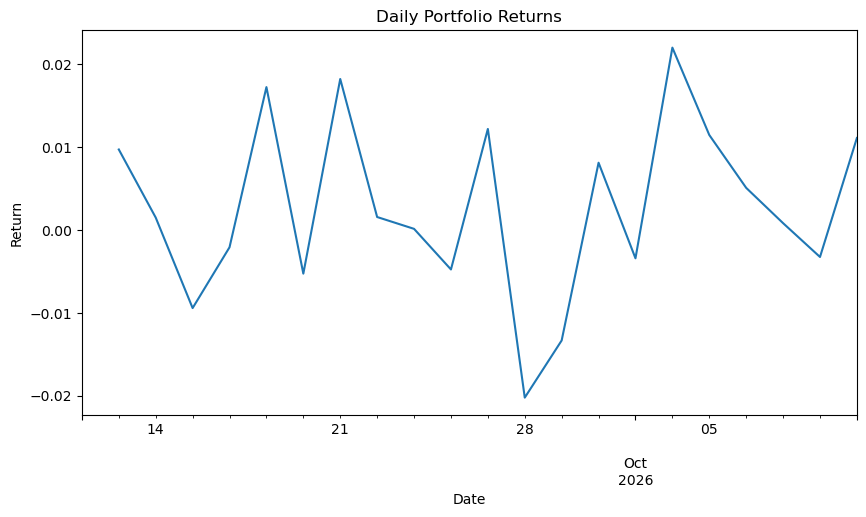

<Figure size 640x480 with 0 Axes>

In [146]:
import matplotlib.pyplot as plt
portfolio_returns.plot(figsize=(10,5))
plt.title("Daily Portfolio Returns")
plt.xlabel("Date")
plt.ylabel("Return")
plt.show()
plt.savefig("daily_portfolio.png")

## Calculate Comulative Returns
Calculate the comulative returns of the portfolio.

In [147]:
cumulative_returns = (1 + portfolio_returns).cumprod()
cumulative_returns.head()

Date
2026-09-10 00:00:00-04:00         NaN
2026-09-11 00:00:00-04:00    1.009701
2026-09-14 00:00:00-04:00    1.011204
2026-09-15 00:00:00-04:00    1.001670
2026-09-16 00:00:00-04:00    0.999572
dtype: float64

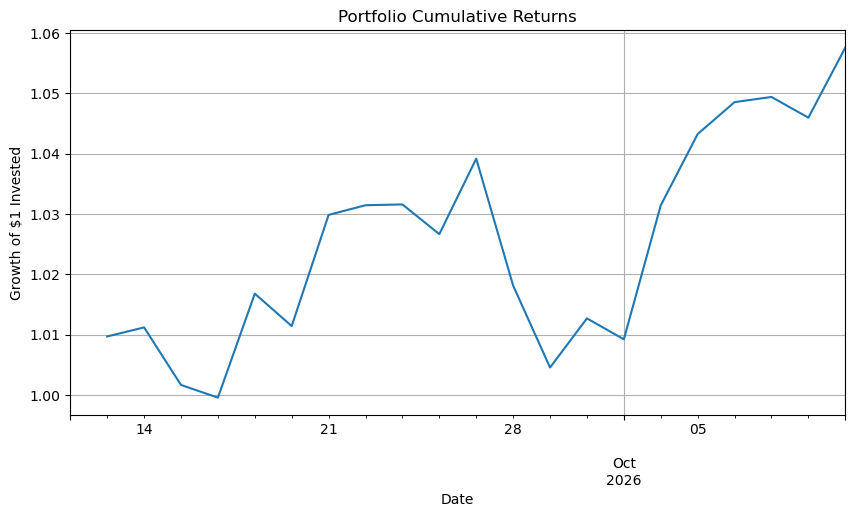

<Figure size 640x480 with 0 Axes>

In [148]:
import matplotlib.pyplot as plt
cumulative_returns.plot(figsize=(10,5))
plt.title("Portfolio Cumulative Returns")
plt.xlabel("Date")
plt.ylabel("Growth of $1 Invested")
plt.grid(True)
plt.show()
plt.savefig("portfolio_cumulative.png")

## Measure Portfolio risk 
Measure the Portfolio risk using the standard deviation of daily returns.

In [149]:
portfolio_risk = portfolio_returns.std()
print(f"Daily Portfolio Risk:{portfolio_risk:.4f}")

Daily Portfolio Risk:0.0107


## Generate Random Portfolio weights
Generate random portfolio weights that sum to one.

In [150]:
import numpy as np 
weights = np.random.random(3)
weights = weights / np.sum(weights)
print(weights)
print("Sum of weights:", np.sum(weights))

[0.18205878 0.46212909 0.35581214]
Sum of weights: 1.0


## Generate 5000 Random Portfolios and Calculate Portfolio Return and Risk
Generate 5000 random portfolios with different asset weight.
  Calculate the expected return and risk for each randomly generated portfolio.

In [151]:
num_portfolio = 5000
weights_list = []
portfolio_returns = []
portfolio_risks = []
sharpe_ratios = []
mean_returns = returns.mean()
cov_matrix = returns.cov()
for i in range(num_portfolio):
    # Generate random weights
    weights = np.random.random(3)
    weights = weights/np.sum(weights)
    # Calculate portfolio return
    portfolio_return = np.dot(weights, mean_returns)
    # Calculate portfolio risk
    portfolio_risk = np.sqrt(np.dot(weights.T, np.dot(cov_matrix, weights)))
    # Calculate Sharpe Ratio
    sharpe = portfolio_return / portfolio_risk
    # Store results
    weights_list.append(weights)
    portfolio_returns.append(portfolio_return)
    portfolio_risks.append(portfolio_risk)
    sharpe_ratios.append(sharpe)




## Identify the Optimal Portfolio
Select the portfolio with the highest Sharpe Ratio.

In [152]:
best_index = np.argmax(sharpe_ratios)
best_return = portfolio_returns[best_index]
best_risk = portfolio_risks[best_index]
best_weights = weights_list[best_index]
best_sharpe = sharpe_ratios[best_index]

In [153]:
print("Best Portfolio")
print(f"Return: {best_return:.4f}")
print(f"Risk: {best_risk:.4f}")
print(f"Sharp Ratio: {best_sharpe:.4f}")
print("\nWeights:")
print(f"AAPL : {best_weights[0]:.2%}")
print(f"MSFT : {best_weights[1]:.2%}")
print(f"TSLA : {best_weights[2]:.2%}")


Best Portfolio
Return: 0.0035
Risk: 0.0116
Sharp Ratio: 0.2986

Weights:
AAPL : 19.34%
MSFT : 74.33%
TSLA : 6.33%


## Compare Portfolio Performance
Compare the optimized portfolio with the equal-weight portfolio.

In [154]:
equal_weights = np.array([1/3, 1/3, 1/3])
equal_return = np.dot(equal_weights, mean_returns)
equal_risk = np.sqrt(np.dot(equal_weights.T, np.dot(cov_matrix, equal_weights)))
equal_sharpe = equal_return / equal_risk

In [155]:
## result

In [156]:
print("Equal Weight Portfolio")
print(f"Return: {equal_return:.4f}")
print(f"Risk: {equal_risk:.4f}")
print(f"Sharp Ratio: {equal_sharpe:.4f}")
print("\nOptimized Portfolio")
print(f"Return: {best_return:.4f}")
print(f"Risk: {best_risk:.4f}")
print(f"Sharpe Ratio: {best_sharpe:.4f}")

Equal Weight Portfolio
Return: 0.0027
Risk: 0.0107
Sharp Ratio: 0.2538

Optimized Portfolio
Return: 0.0035
Risk: 0.0116
Sharpe Ratio: 0.2986


## Create a Results DataFrame
Store the performance metrics of all generated portfolios in a structured DataFrame.

In [157]:
results = pd.DataFrame({
    "Return": portfolio_returns,
    "Risk": portfolio_risks,
    "Sharpe": sharpe_ratios,
    "AAPL": [w[0] for w in weights_list], "MSFT": [w[1] for w in weights_list], "TSLA": [w[2] for w in weights_list]
})
results.head()
results.describe()


,Return,Risk,Sharpe,AAPL,MSFT,TSLA
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,0.002715,0.011292,0.242434,0.339531,0.332435,0.328034
std,0.000400,0.001408,0.036701,0.179816,0.180881,0.180274
min,0.001540,0.009442,0.143053,0.000129,0.000010,0.000034
25%,0.002447,0.010207,0.216676,0.211866,0.201653,0.191804
50%,0.002717,0.011005,0.247969,0.339424,0.330397,0.329105
75%,0.002978,0.012050,0.272616,0.452792,0.448787,0.445694
max,0.003977,0.018264,0.298562,0.980123,0.954021,0.963584


## Visualize the Efficient Frontier
Visualize all simulated portfolios based on their risk and return.

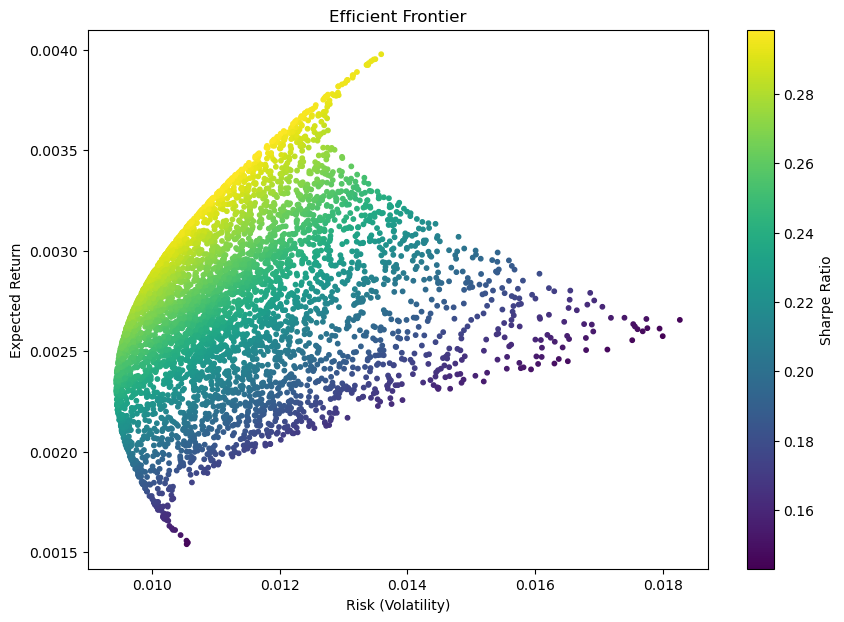

<Figure size 640x480 with 0 Axes>

In [158]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10,7))
plt.scatter(
    results["Risk"],
    results["Return"],
    c=results["Sharpe"],
    cmap="viridis",
    s=10
)
plt.colorbar(label="Sharpe Ratio")
plt.xlabel("Risk (Volatility)")
plt.ylabel("Expected Return")
plt.title("Efficient Frontier")
plt.show()
plt.savefig("efficient_frontier.png")

## Visualize the Portfolio Optimization
Visualize Portfolio Optimization based on their risk, return, and sharpe ratio.

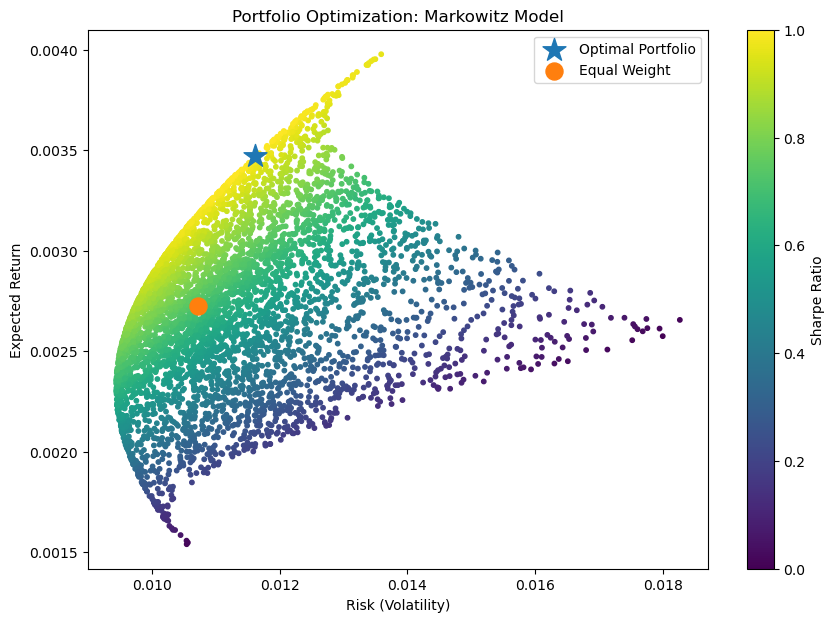

<Figure size 640x480 with 0 Axes>

In [159]:
plt.figure(figsize=(10,7))
plt.scatter(
    results["Risk"],
    results["Return"],
    c=results["Sharpe"],
    cmap="viridis",
    s=10
)

plt.scatter(best_risk, best_return, marker="*",
            s=300, label="Optimal Portfolio"
           )

plt.scatter(equal_risk, equal_return, marker="o",
            s=150, label="Equal Weight"
           )

plt.xlabel("Risk (Volatility)")
plt.ylabel("Expected Return")
plt.title("Portfolio Optimization: Markowitz Model")
plt.legend()
plt.colorbar(label="Sharpe Ratio")
plt.show()
plt.savefig("portfolio_optimization.png")

## Identify the Efficient Frontier
Identify portfoliosthat provide the highest return for a given level of risk.

In [160]:
results_sorted = results.sort_values("Risk")

results_sorted["Max_Return"] = results_sorted["Return"].cummax()

efficient_frontier = results_sorted[
    results_sorted["Return"] >= results_sorted["Max_Return"]
]

In [161]:
efficient_frontier.head()
efficient_frontier.shape

(267, 7)

## Visualize the Efficient Frontier
The simulated portfolios are plotted according to their risk and expected return.

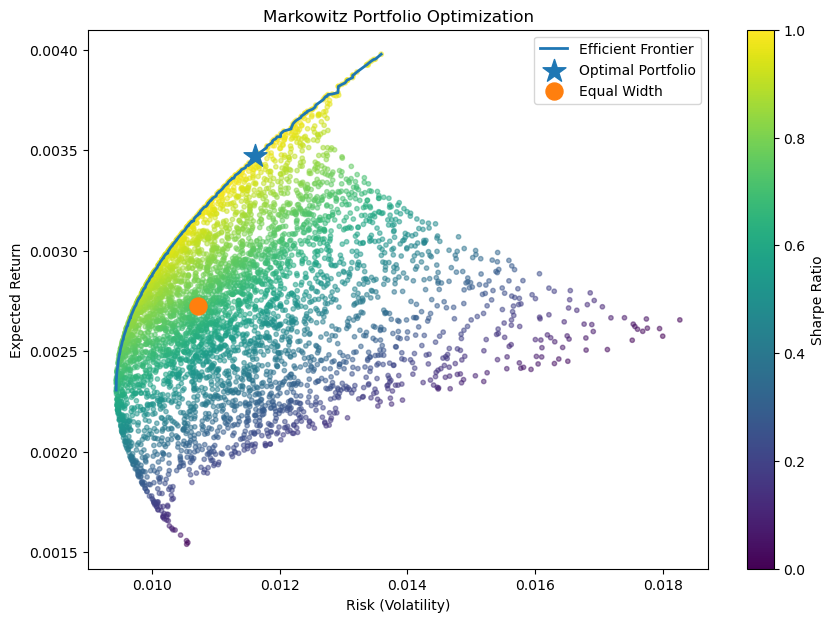

<Figure size 640x480 with 0 Axes>

In [162]:
plt.figure(figsize=(10, 7))

plt.scatter(
    results["Risk"],
    results["Return"],
    c=results["Sharpe"],
    cmap="viridis",
    s=10,
    alpha=0.5
)

plt.plot(
    efficient_frontier["Risk"],
    efficient_frontier["Return"],
    linewidth=2,
    label="Efficient Frontier")

plt.scatter(
    best_risk, best_return, marker="*", s=300, label="Optimal Portfolio")

plt.scatter(
    equal_risk, equal_return, marker="o" , s=150, label="Equal Width")

plt.xlabel("Risk (Volatility)")
plt.ylabel("Expected Return")
plt.title("Markowitz Portfolio Optimization")
plt.colorbar(label="Sharpe Ratio")
plt.legend()
plt.show()
plt.savefig("markowitz.png")
        

## Portfolio Performance Comparison
The optimized portfolio is compared with the equal-weight portfolio using three performance measures:
-Expected Return
-Risk(Volatility)
-Sharpe Ratio

In [163]:
comparison = pd.DataFrame({
    "Portfolio": ["Equal Weight", "Optimized"],
    "Return": [equal_return, best_return],
    "Risk": [equal_risk, best_risk],
    "Sharpe Ratio": [equal_sharpe, best_sharpe]
})

comparison

,Portfolio,Return,Risk,Sharpe Ratio
0,Equal Weight,0.002723,0.010730,0.253766
1,Optimized,0.003469,0.011619,0.298562


In [164]:
comparison.round(4)

,Portfolio,Return,Risk,Sharpe Ratio
0,Equal Weight,0.0027,0.0107,0.2538
1,Optimized,0.0035,0.0116,0.2986


## Out-of-Sample Evaluation 
The optimized portfolio was evaluated on unseen test data  and compared with an equal-weight portfolio.

In [165]:
split_index = int(len(returns) * 0.8)

train_returns = returns.iloc[:split_index]
test_returns = returns.iloc[split_index:]
print("Train data:", train_returns.shape)
print("Test data:", test_returns.shape)

Train data: (17, 3)
Test data: (5, 3)


In [166]:
train_mean_returns = train_returns.mean()
train_cov_matrix = train_returns.cov()
print(train_mean_returns)
print(train_cov_matrix)

AAPL    0.001410
MSFT    0.003205
TSLA    0.001388
dtype: float64
          AAPL      MSFT      TSLA
AAPL  0.000131  0.000088  0.000109
MSFT  0.000088  0.000203  0.000064
TSLA  0.000109  0.000064  0.000408


In [167]:
np.random.seed(42)

train_weights_list = []
train_sharpes = []

num_portfolios = 5000

for i in range(num_portfolios):

    weights = np.random.random(3)
    weights = weights / np.sum(weights)

    portfolio_return = np.dot(weights, train_mean_returns)

    portfolio_risk = np.sqrt(
        np.dot(weights.T, np.dot(train_cov_matrix, weights))
    )

    sharpe = portfolio_return / portfolio_risk

    train_weights_list.append(weights)
    train_sharpes.append(sharpe)

In [168]:
train_best_index = np.argmax(train_sharpes)

train_best_weights = train_weights_list[train_best_index]
train_best_sharpe = train_sharpes[train_best_index]

print("Best training weights:", train_best_weights)
print("Best training Sharpe:", train_best_sharpe)

Best training weights: [0.00447784 0.92598649 0.06953567]
Best training Sharpe: 0.225723359460134


In [169]:
test_mean_returns = test_returns.mean()

print(test_mean_returns)

AAPL    0.001794
MSFT    0.006768
TSLA    0.006534
dtype: float64


In [170]:
test_portfolio_return = np.dot(
    train_best_weights,
    test_mean_returns
)

print("Test portfolio return:", test_portfolio_return)

Test portfolio return: 0.006729630634209085


In [171]:
test_equal_return = np.dot(
    equal_weights,
    test_mean_returns
)

print("Test equal-weight return:", test_equal_return)

Test equal-weight return: 0.005032221459935226


In [172]:
test_cov_matrix = test_returns.cov()

test_equal_risk = np.sqrt(
    np.dot(
        equal_weights.T,
        np.dot(test_cov_matrix, equal_weights)
    )
)

test_optimized_risk = np.sqrt(
    np.dot(
        train_best_weights.T,
        np.dot(test_cov_matrix, train_best_weights)
    )
)

print("Test equal-weight risk:", test_equal_risk)
print("Test optimized risk:", test_optimized_risk)

Test equal-weight risk: 0.006413475534507511
Test optimized risk: 0.013976160089893759


In [173]:
test_equal_sharpe = test_equal_return / test_equal_risk

test_optimized_sharpe = test_portfolio_return / test_optimized_risk

print("Test equal-weight Sharpe:", test_equal_sharpe)
print("Test optimized Sharpe:", test_optimized_sharpe)

Test equal-weight Sharpe: 0.7846325183372901
Test optimized Sharpe: 0.48150783841373707


## Monte Carlo Sensitivity Analysis
The Monte Carlo optimozation was repeated using a different random seed

In [174]:
np.random.seed(123)

num_portfolios = 10000

sensitivity_weights = []
sensitivity_sharpes = []

for i in range(num_portfolios):

    weights = np.random.random(3)
    weights = weights / np.sum(weights)

    portfolio_return = np.dot(
        weights,
        train_mean_returns
    )

    portfolio_risk = np.sqrt(
        np.dot(
            weights.T,
            np.dot(train_cov_matrix, weights)
        )
    )

    sharpe = portfolio_return / portfolio_risk

    sensitivity_weights.append(weights)
    sensitivity_sharpes.append(sharpe)


sensitivity_best_index = np.argmax(sensitivity_sharpes)

sensitivity_best_weights = sensitivity_weights[sensitivity_best_index]
sensitivity_best_sharpe = sensitivity_sharpes[sensitivity_best_index]

print("Best weights:", sensitivity_best_weights)
print("Best Sharpe:", sensitivity_best_sharpe)

Best weights: [0.01256072 0.923085   0.06435428]
Best Sharpe: 0.2256995403150255


In [175]:
np.random.seed(42)

num_portfolios = 1000

In [176]:
print("Best weights:", train_weights_list[train_best_index])
print("Best Sharpe:", train_best_sharpe)

Best weights: [0.00447784 0.92598649 0.06953567]
Best Sharpe: 0.225723359460134
